In [24]:
import numpy as np
import matplotlib.pyplot as plt

FILE = "mindist.xvg"
CUTOFF = 0.45       # nm, contact threshold
T_SPLIT = 225.0     # ns, "before / after" boundary

In [25]:
data = np.loadtxt(FILE, comments=("#", "@"))
t = data[:, 0] / 1000       # пс -> нс
d = data[:, 1]      # dist
print(f'number of frames: {len(t)}, length: {t[-1] - t[0]} ns')

number of frames: 250001, length: 500.0 ns


In [26]:
contact = d < CUTOFF
before = t < T_SPLIT
after = ~before

print(f"Contact time fraction (<{CUTOFF} nm):")
print(f"  before {T_SPLIT:.0f} ns:   {contact[before].mean():.3f}")
print(f"  after {T_SPLIT:.0f} ns: {contact[after].mean():.3f}")

no_contact = np.where(~contact)[0]
if len(no_contact) == 0:
    print("Peptides are in contact across all frames")
elif no_contact[-1] + 1 < len(t):
    print(f"Permanent contact begins at t = {t[no_contact[-1] + 1]:.1f} ns")
else:
    print("No contact at the end of the trajectory")

events = np.sum(np.diff(contact.astype(int)) == 1)
print(f"Number of contact formation events: {events}")

Contact time fraction (<0.45 nm):
  before 225 ns:   0.148
  after 225 ns: 1.000
Permanent contact begins at t = 223.6 ns
Number of contact formation events: 556


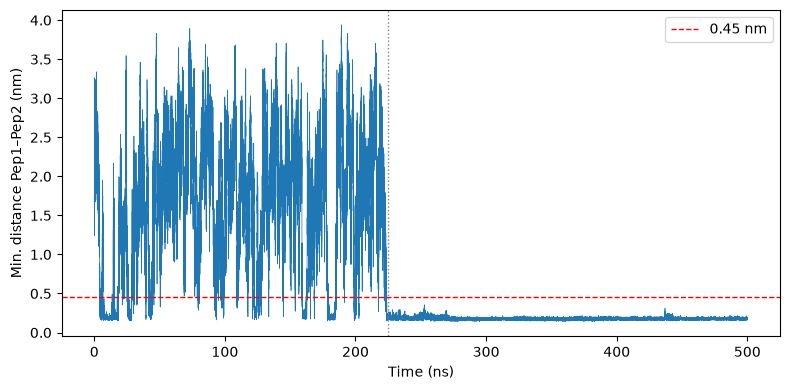

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, d, lw=0.5)
ax.axhline(CUTOFF, color="r", ls="--", lw=1, label=f"{CUTOFF} nm")
ax.axvline(T_SPLIT, color="gray", ls=":", lw=1)
ax.set_xlabel("Time (ns)")
ax.set_ylabel("Min. distance Pep1–Pep2 (nm)")
ax.legend()
fig.tight_layout()
fig.savefig("mindist.png", dpi=200)
plt.show()